In [149]:
from IPython.display import HTML, display

display(HTML(r"""
<style>
/* Título principal: # */
.jp-RenderedHTMLCommon h1,
.rendered_html h1,
.reveal h1 {
    font-size: 2.15em !important;
    line-height: 1.12 !important;
    margin-bottom: 0.35em !important;
    color: #4E8DBD !important;
}

/* Subtítulo o sección: ## */
.jp-RenderedHTMLCommon h2,
.rendered_html h2,
.reveal h2 {
    font-size: 1.55em !important;
    line-height: 1.18 !important;
    margin-bottom: 0.45em !important;
}

/* Encabezado menor: ### */
.jp-RenderedHTMLCommon h3,
.rendered_html h3,
.reveal h3 {
    font-size: 1.25em !important;
}

/* Texto normal, listas, tablas y citas */
.jp-RenderedHTMLCommon p,
.jp-RenderedHTMLCommon li,
.jp-RenderedHTMLCommon td,
.jp-RenderedHTMLCommon th,
.jp-RenderedHTMLCommon blockquote,
.rendered_html p,
.rendered_html li,
.rendered_html td,
.rendered_html th,
.rendered_html blockquote,
.reveal p,
.reveal li,
.reveal td,
.reveal th,
.reveal blockquote {
    font-size: 1.18em !important;
    line-height: 1.35 !important;
}
</style>
"""))

<div style="text-align: center;">

<h1><em>Modelos matemáticos de enfermedades infecciosas con Python</em></h1>

<h2>Clase 2: Ajuste determinista, predicción e incertidumbre</h2>

<br><br>

<h3>María Luisa Daza Torres</h3>

<br><br>

<h4> Escuela de Invierno en Matemáticas </h4>

<br><br>

<h4> 4 de noviembre de 2026</h4>

</div>


<img src="Logo_IM_Cuerna.png" style="width: 20%; display: block; margin: auto;">








# De la dinámica a los datos

En la clase anterior construimos el modelo SIR para describir la evolución
de una epidemia mediante los compartimentos $S(t)$, $I(t)$ y $R(t)$.
<br><br>
Pero, en la práctica, no observamos directamente esos tres compartimentos.
Lo que solemos tener son registros de casos reportados por día.
<br><br><br>
Hoy haremos el puente entre ambos:

$$
\text{modelo SIR}
\quad \longrightarrow \quad
\text{incidencia predicha}
\quad \longrightarrow \quad
\text{casos observados}.
$$
<br><br><br>
La pregunta central será:
<br><br><br>
$$
\text{¿qué valor de } \beta \text{ hace que el modelo sea compatible con los datos?}
$$
<br><br><br>


# Leemos librerias a usar y definimos el tamaño de las figuras a mostrar

In [150]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

plt.rcParams.update({
    'figure.figsize': (10, 5), 'font.size': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
})
rng = np.random.default_rng(2026)

# Un laboratorio controlado

Antes de trabajar con datos reales, construiremos un ejemplo para el cual conocemos el mecanismo que los generó.

Esto nos permitirá separar dos preguntas: $\textcolor{pink}{\text{cómo se ajusta el modelo y qué tan bien recupera un parámetro que conocemos.}}$

Usaremos exactamente el modelo presentado en Clase 1:

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}, \qquad\\
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I, \qquad
\frac{dR}{dt}=\gamma I.
$$

El modelo genera una trayectoria determinista a partir de:

 - $N$
 - $y_0=(S_0,I_0,R_{\mathrm{init}})$
  - $\beta$ y $\gamma$.

En este primer ajuste consideraremos conocidos:

 - $N=10000$
 - $y_0= (S_0,I_0,R_{\mathrm{init}})=(N-10, 10, 0)$
 - $\gamma=1/4$ (duración infecciosa media de 4 días)

por tanto, **sólo estimaremos $\beta$**. Generaremos datos sintéticos usando $\beta_{true}= 0.4$


In [151]:
N = 1_000
I0 = 10
R_init = 0
S0 = N - I0 - R_init
dias = 100

beta_true = 0.40
gamma = 1 / 4                 # conocido: duración infecciosa media de 4 días
pars_true = {'beta': beta_true, 'gamma': gamma}
y0 = [S0, I0, R_init]
t_eval = np.arange(0, dias + 1)

def sir(t, y, pars):
    beta = pars['beta']
    gamma = pars['gamma']
    S, I, R = y
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    return [dS, dI, dR]

def int_SIR(t_eval, y0, pars):
    return solve_ivp(sir, [t_eval[0], t_eval[-1]], y0, t_eval=t_eval,
                     args=(pars,), rtol=1e-8, atol=1e-10)

# ¿Qué compara el ajuste?
<br><br>
$$
\underbrace{S(t),\,I(t),\,R(t)}_{\text{estado del modelo}}
\quad \longrightarrow \quad
\underbrace{G_j(\beta)}_{\text{incidencia predicha}}
\quad \longrightarrow \quad
\underbrace{Y_j}_{\text{casos observados}}.
$$
<br><br><br>
- **Prevalencia:** $I(t)$ es el número de personas infecciosas en el instante $t$.
<br><br>
- **Incidencia:** $G_j(\beta)$ es el número de infecciones nuevas que el
  modelo predice durante el intervalo $[t_{j-1},t_j]$.
<br><br>
- **Casos observados:** $Y_j$ es el número de casos reportados en ese
  intervalo; no coincide necesariamente con la incidencia real.

<br><br><br>
____

# Del modelo SIR a los casos diarios
<br><br>
El modelo SIR produce trayectorias continuas $S(t)$, $I(t)$ y $R(t)$. La tasa instantánea de nuevas infecciones es
<br><br>
$$
\lambda(t;\beta)=\beta\frac{S(t;\beta)I(t;\beta)}{N}.
$$
<br><br>
Los datos diarios, en cambio, registran los casos que ocurrieron durante un intervalo completo. Para el día $j$, asociado al intervalo $[t_{j-1},t_j]$, definimos la incidencia que predice el modelo como
<br><br>
$$
G_j(\beta)
=
\int_{t_{j-1}}^{t_j}\lambda(t;\beta)\,dt
=
S(t_{j-1};\beta)-S(t_j;\beta).
$$
<br><br>
**La segunda igualdad usa $\frac{dS}{dt}=-\beta SI/N$. Esto es especialmente útil en el código: al resolver el modelo en tiempos diarios, los casos nuevos se obtienen como las disminuciones sucesivas de S**


____


# Una función de predicción
<br><br>
Cada valor de $\beta$ produce una serie completa de incidencias diarias. Reunimos esas predicciones en el vector
<br><br>
$$
\mathbf{G}(\beta)=\bigl(G_1(\beta),\ldots,G_m(\beta)\bigr).
$$
<br><br>
La función $G(\beta)$ del código implementa este cálculo: resuelve el sistema SIR y devuelve las disminuciones diarias de $S$. Por ahora, $\gamma$, $N$ y $y_0=(S_0,I_0,R_{\mathrm{init}})$ permanecen fijos, de modo que el único parámetro que varía es $\beta$.
<br><br>
Esta es la curva determinista que compararemos con los datos.


Text(0, 0.5, 'Incidencia')

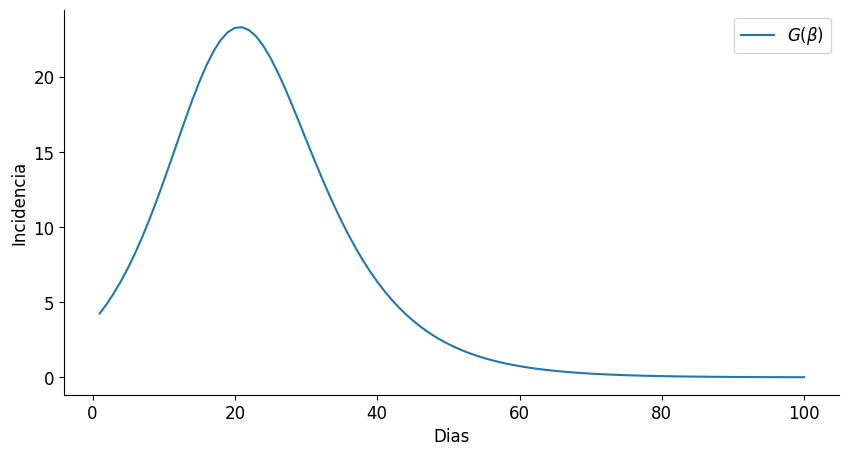

In [152]:
def Fm(beta): # G
    """Devuelve la solución SIR y C_j = S(t_{j-1}) - S(t_j)."""
    pars = {'beta': beta, 'gamma': gamma}
    sol = int_SIR(t_eval, y0, pars)
    S, I, R = sol.y

    return sol

def G(beta):
    S,I,R = Fm(beta).y
    incidencia = np.maximum(-np.diff(S), 0)
    return incidencia

incidencia_true = G(beta_true)
plt.plot(t_eval[1:], incidencia_true, label=r'$G(\beta)$')
plt.legend()
plt.xlabel('Dias')
plt.ylabel('Incidencia')


# Del modelo determinista a los datos observados
<br><br>
- La cantidad $G_j(\beta)$ es determinista: una vez fijado $\beta$, el modelo predice un único número de infecciones nuevas para cada día.


- Los casos que observamos, sin embargo, no coinciden exactamente con esa curva.


- Hay variación debida a medición, reporte, subregistro y otros procesos que el modelo SIR no representa de forma explícita.



# Un primer modelo de observación

Como primera aproximación, suponemos que el caso observado el día $j$ es la predicción del modelo más un error aleatorio:

$$
\textcolor{pink}{Y_j=G_j(\beta)+\varepsilon_j,}
$$

donde

$$
\varepsilon_j\overset{\mathrm{ind}}{\sim}\mathcal{N}(0,\sigma^2).
$$

Equivalentemente,

$$
Y_j\mid\beta,\sigma\overset{\mathrm{ind}}{\sim}\mathcal{N}\bigl(G_j(\beta),\sigma^2\bigr).
$$

El parámetro $\sigma$ controla cuánto se dispersan los datos alrededor de la curva predicha. **El supuesto gaussiano es una simplificación útil para introducir el ajuste; más adelante podremos discutir modelos de observación más apropiados para conteos.**

## Datos sintéticos

Para probar el procedimiento, fijamos un valor generador $\beta_{\mathrm{true}}$. Con los demás elementos del modelo fijos, resolvemos el SIR y obtenemos

$$
G_j(\beta_{\mathrm{true}}).
$$

Después agregamos error de observación independiente:

$$
Y_j^{\mathrm{syn}}=G_j(\beta_{\mathrm{true}})+\varepsilon_j,
\qquad
\varepsilon_j\overset{\mathrm{ind}}{\sim}\mathcal{N}(0,\sigma^2).
$$

Aunque conocemos $\beta_{\mathrm{true}}$, el procedimiento de ajuste sólo verá las observaciones ruidosas $Y_1^{\mathrm{syn}},\ldots,Y_m^{\mathrm{syn}}$. La siguiente pregunta es si esos datos bastan para recuperar un valor $\widehat\beta$ cercano a $\beta_{\mathrm{true}}$.


In [153]:
# Primer modelo de observación: incidencia real más un pequeño error gaussiano.
sigma_observacion = 2.5
media = G(beta_true)
casos_observados = np.maximum(
    media + rng.normal(0, sigma_observacion, size=media.shape),
    0
)

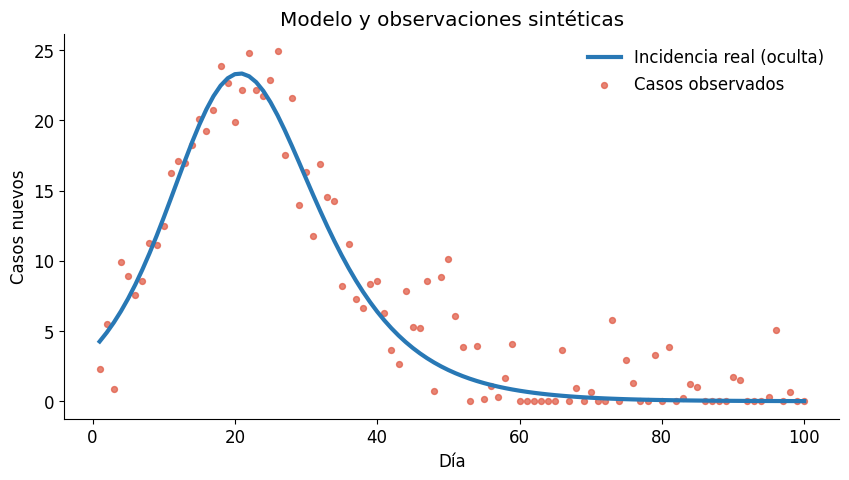

In [154]:
fig, ax = plt.subplots()
ax.plot(t_eval[1:], incidencia_true, lw=3, color='#2878B5',
        label='Incidencia real (oculta)')
ax.scatter(t_eval[1:], casos_observados, s=18, color='#E05C47',
           alpha=0.75, label='Casos observados')
ax.set(xlabel='Día', ylabel='Casos nuevos', title='Modelo y observaciones sintéticas')
ax.legend(frameon=False)
plt.show()

# De los datos a una predicción

El conjunto sintético contiene las observaciones $Y_1^{\mathrm{syn}},\ldots,Y_m^{\mathrm{syn}}$. Para evaluar si el ajuste predice datos que no utilizó, reservamos los primeros $n_{\mathrm{ent}}=28$ días para entrenamiento y dejamos los días restantes para prueba.

Para cada valor candidato de $\beta$, el modelo produce la incidencia diaria $G_j(\beta)$. En entrenamiento medimos la discrepancia con los datos mediante

$$
Q_{\mathrm{ent}}(\beta)
=
\sum_{j=1}^{n_{\mathrm{ent}}}
\left[Y_j^{\mathrm{syn}}-G_j(\beta)\right]^2.
$$

Elegimos el valor que hace mínima esta suma de residuos al cuadrado:

$$
\widehat\beta
=
\underset{\beta>0}{\operatorname*{argmin}}\;Q_{\mathrm{ent}}(\beta).
$$

Durante esta optimización, $\gamma$, $N$ y $y_0=(S_0,I_0,R_{\mathrm{init}})$ se mantienen fijos: **sólo estimamos $\beta$**. Como $\gamma$ es conocido, también podemos reportar $\widehat R_0=\widehat\beta/\gamma$.

La curva ajustada es $G_j(\widehat\beta)$ en todo el periodo. Los datos de entrenamiento sirvieron para obtener $\widehat\beta$; los datos de prueba sólo sirven para valorar la predicción fuera de muestra.


In [155]:
n_entrenamiento = 28

def perdida(beta, observaciones, n_entrenamiento):
    prediccion = G(beta)
    residuos = observaciones[:n_entrenamiento] - prediccion[:n_entrenamiento]
    return np.sum(residuos ** 2)

ajuste = minimize_scalar(perdida, bounds=(0.05, 1.0), method='bounded',
                         args=(casos_observados, n_entrenamiento))
beta_estimado = ajuste.x
incidencia_ajustada = G(beta_estimado)
sol_ajustado = Fm(beta_estimado)
modelo_ajustado = {'tiempo': sol_ajustado.t, 'S': sol_ajustado.y[0],
                   'I': sol_ajustado.y[1], 'R': sol_ajustado.y[2],
                   'dia_incidencia': t_eval[1:], 'incidencia': incidencia_ajustada}

print(f'beta estimado = {beta_estimado:.3f}')
print(f'R₀ estimado = {beta_estimado / gamma:.2f}')

beta estimado = 0.399
R₀ estimado = 1.60


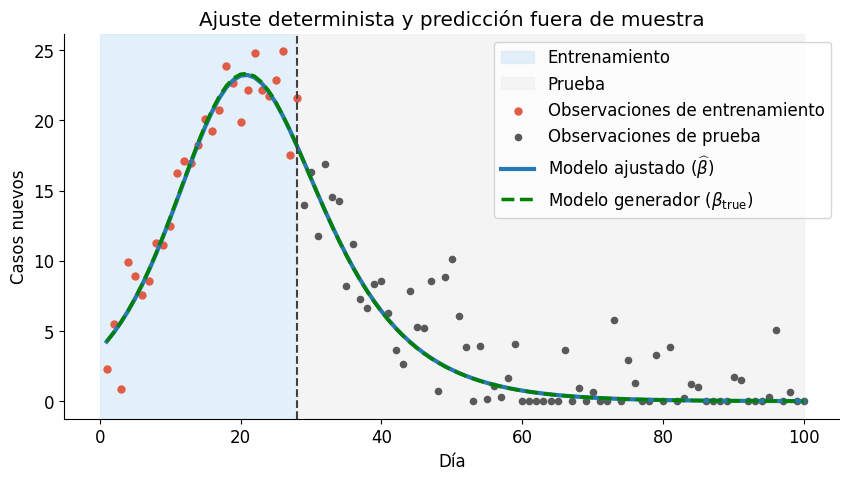

In [156]:
dias_incidencia = t_eval[1:]
mask_train = np.arange(dias) < n_entrenamiento
fig, ax = plt.subplots()
ax.axvspan(0, n_entrenamiento, color='#D9EAF7', alpha=0.7, label='Entrenamiento')
ax.axvspan(n_entrenamiento, dias, color='#F2F2F2', alpha=0.8, label='Prueba')
ax.scatter(dias_incidencia[mask_train], casos_observados[mask_train], color='#E05C47', s=25, label='Observaciones de entrenamiento')
ax.scatter(dias_incidencia[~mask_train], casos_observados[~mask_train], color='0.35', s=20, label='Observaciones de prueba')

ax.plot(dias_incidencia, modelo_ajustado['incidencia'], color='#2878B5', lw=3,
        label=r'Modelo ajustado ($\widehat{\beta}$)')

ax.plot(dias_incidencia, incidencia_true, color='green', lw=2.5, ls='--',
        label=r'Modelo generador ($\beta_{\mathrm{true}}$)')

ax.axvline(n_entrenamiento, color='0.25', ls='--')
ax.set(xlabel='Día', ylabel='Casos nuevos',
       title='Ajuste determinista y predicción fuera de muestra')
ax.legend(frameon=True, ncol=1, loc='upper right')
plt.show()

# Incertidumbre después del ajuste

Hasta ahora hemos elegido un valor, $\widehat\beta$, y con él obtenemos una
curva de incidencia predicha,

$$
\widehat G_j = G_j(\widehat\beta).
$$

Pero esta curva no es una certeza. Los casos observados contienen error: si
volviéramos a observar un proceso epidemiológico similar con otras
realizaciones del error $\varepsilon_j$, los datos cambiarían, la función
objetivo tendría otro mínimo y obtendríamos otra estimación de $\beta$.

Para estudiar esta variación usaremos un **bootstrap paramétrico**.


# Bootstrap paramétrico: repetir la observación en computadora

El bootstrap paramétrico aproxima la variabilidad del ajuste recreando, en
computadora, muchas posibles observaciones del modelo que acabamos de ajustar.

Tomamos la curva ajustada como referencia para generar los datos. En cada
repetición mantenemos fijos $\widehat\beta$ y $\widehat\sigma$, y sólo cambia
una nueva realización del error de observación.

Partimos de los $m$ datos de entrenamiento. Primero ajustamos el modelo y
obtenemos $\widehat\beta$. Los residuos del ajuste son

$$
r_j = Y_j-G_j(\widehat\beta),
\qquad j=1,\ldots,m,
$$

y estimamos la desviación estándar del error mediante

$$
\overline r = \frac{1}{m}\sum_{j=1}^{m} r_j,
\qquad
\widehat\sigma
=
\sqrt{
\frac{1}{m-1}
\sum_{j=1}^{m}
\left(r_j-\overline r\right)^2
}.
$$

La incidencia media predicha por el modelo ajustado es

$$
\widehat G_j = G_j(\widehat\beta).
$$

Después, para $b=1,\ldots,B$, repetimos:

1. Simulamos una nueva serie de casos alrededor de la curva ajustada,

$$
Y_j^{(b)}
=
\widehat G_j+\varepsilon_j^{(b)},
\qquad
\varepsilon_j^{(b)}
\overset{\mathrm{ind}}{\sim}
\mathcal{N}(0,\widehat\sigma^2).
$$

2. Reajustamos $\beta$ a la nueva serie simulada, usando el mismo
   procedimiento y los mismos días de entrenamiento.

3. Guardamos la nueva estimación $\widehat\beta^{(b)}$ y la curva resultante,

$$
\widehat G_j^{(b)}
=
G_j\bigl(\widehat\beta^{(b)}\bigr).
$$

Las diferencias entre $\widehat\beta^{(1)},\ldots,\widehat\beta^{(B)}$ se deben
únicamente a las nuevas realizaciones simuladas del error de observación.



In [159]:
n_bootstrap = 80
pred_media = modelo_ajustado['incidencia']
residuos_entrenamiento = casos_observados[:n_entrenamiento] - pred_media[:n_entrenamiento]
sigma_estimado = residuos_entrenamiento.std(ddof=1)
betas_bootstrap = []
for _ in range(n_bootstrap):
    muestra = np.maximum(pred_media + rng.normal(0, sigma_estimado, size=dias), 0)
    resultado = minimize_scalar(perdida, bounds=(0.05, 1.0), method='bounded',
                                args=(muestra, n_entrenamiento))
    betas_bootstrap.append(resultado.x)

betas_bootstrap = np.array(betas_bootstrap)
curvas_bootstrap = np.array([
    G(beta_bootstrap)
    for beta_bootstrap in betas_bootstrap])


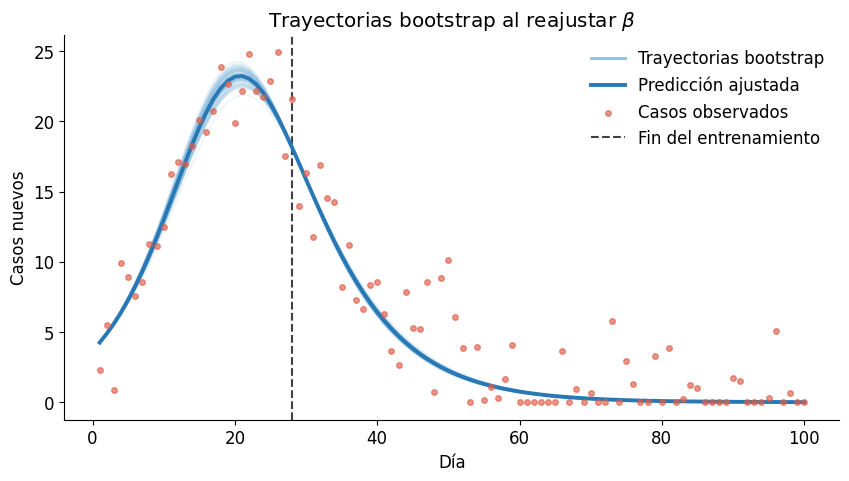

In [161]:
fig, ax = plt.subplots()
for curva in curvas_bootstrap:
    ax.plot(dias_incidencia, curva, color='#8DBFE0', lw=1, alpha=0.18, zorder=1)

ax.plot([], [], color='#8DBFE0', lw=2, label='Trayectorias bootstrap')
ax.plot(dias_incidencia, pred_media, color='#2878B5', lw=2.8,
        label='Predicción ajustada', zorder=3)
ax.scatter(dias_incidencia, casos_observados, color='#E05C47', s=16,
           alpha=0.65, label='Casos observados', zorder=4)
ax.axvline(n_entrenamiento, color='0.25', ls='--',
           label='Fin del entrenamiento', zorder=2)
ax.set(xlabel='Día', ylabel='Casos nuevos',
       title=r'Trayectorias bootstrap al reajustar $\beta$')
ax.legend(frameon=False, loc='best')
plt.show()

## ¿Cómo interpretamos el resultado?

Después de $B$ repeticiones tenemos

$$
\widehat\beta^{(1)},\ldots,\widehat\beta^{(B)},
$$

que muestran cuánto podría variar la estimación de $\beta$ debido al error de
observación.

Para cada día $j$, calculamos los percentiles 5 y 95 de las curvas

$$
\widehat G_j^{(1)},\ldots,\widehat G_j^{(B)}.
$$

Estos percentiles forman una banda bootstrap central de 90% para la
**incidencia media predicha por el modelo**.

La banda no es un intervalo para futuros casos observados: esos casos tendrían
además nuevo error de observación y, por tanto, variarían más.

<br>

Esta incertidumbre sólo incorpora el ruido de observación bajo los supuestos
que fijamos. Mantiene constantes $\gamma$, $N$, $y_0$ y la estructura del
modelo SIR; no incorpora subregistro, retrasos de reporte ni mecanismos
ausentes del modelo.

Aunque en este ejemplo conocemos $\beta_{\mathrm{true}}$ porque los datos son
sintéticos, el bootstrap no lo utiliza: en una aplicación real sólo contamos
con $\widehat\beta$ y $\widehat\sigma$.

In [162]:
banda_baja, banda_alta = np.percentile(curvas_bootstrap, [5, 95], axis=0)
intervalo_beta = np.percentile(betas_bootstrap, [5, 95])

print(f'Desviación estándar estimada del error: {sigma_estimado:.2f}')
print('Intervalo bootstrap central de 90% para beta:',
      f'({intervalo_beta[0]:.3f}, {intervalo_beta[1]:.3f})')

Desviación estándar estimada del error: 2.00
Intervalo bootstrap central de 90% para beta: (0.396, 0.403)


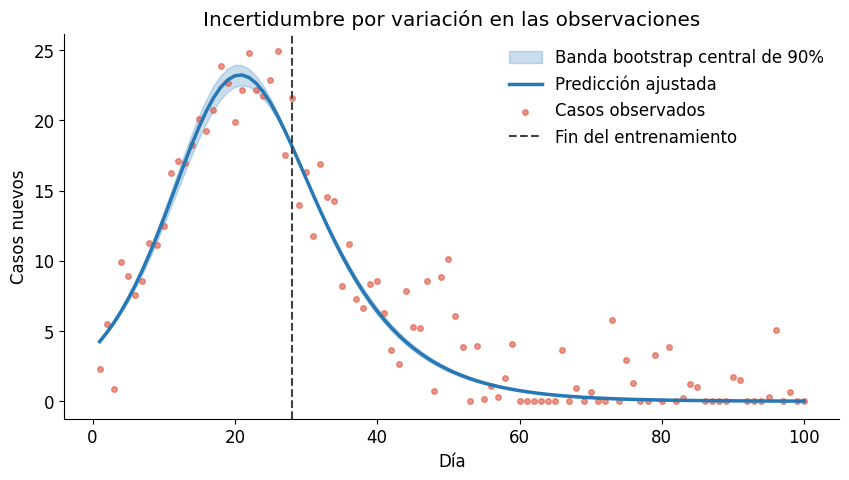

In [164]:
fig, ax = plt.subplots()
ax.fill_between(dias_incidencia, banda_baja, banda_alta, color='#2878B5', alpha=0.25,
                label='Banda bootstrap central de 90%')
ax.plot(dias_incidencia, pred_media, color='#2878B5', lw=2.5, label='Predicción ajustada')
ax.scatter(dias_incidencia, casos_observados, color='#E05C47', s=16, alpha=0.65,
           label='Casos observados')
ax.axvline(n_entrenamiento, color='0.25', ls='--', label='Fin del entrenamiento')
ax.set(xlabel='Día', ylabel='Casos nuevos',
       title='Incertidumbre por variación en las observaciones')
ax.legend(frameon=False)
plt.show()

# Cierre: de SIR a los datos


$$
(S,I,R)
\longrightarrow
G_j(\beta)
\longrightarrow
Y_j
\longrightarrow
\widehat\beta
\longrightarrow
G_j(\widehat\beta).
$$

- El SIR produce una incidencia diaria; el modelo de observación la conecta con los datos;

- los datos de entrenamiento permiten estimar $\widehat\beta$ mientras mantenemos fijos $\gamma$, $N$ y $y_0$.

 - Los datos de prueba y el bootstrap nos recuerdan que un buen ajuste no elimina la incertidumbre.

En la siguiente clse, MCMC/HMC reemplazará la estimación puntual por una distribución de valores plausibles para los parámetros y las predicciones.